In [ ]:
!nvidia-smi

Sun Sep  1 08:24:40 2024       
+---------------------------------------------------------------------------------------+
| NVIDIA-SMI 535.104.05             Driver Version: 535.104.05   CUDA Version: 12.2     |
|-----------------------------------------+----------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id        Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |         Memory-Usage | GPU-Util  Compute M. |
|                                         |                      |               MIG M. |
|=========================================+======================+======================|
|   0  NVIDIA A100-SXM4-40GB          Off | 00000000:00:04.0 Off |                    0 |
| N/A   33C    P0              47W / 400W |      2MiB / 40960MiB |      0%      Default |
|                                         |                      |             Disabled |
+-----------------------------------------+----------------------+--

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!pip install ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.8/41.8 kB 3.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 872.3/872.3 kB 52.5 MB/s eta 0:00:00


In [ ]:
import os
from ultralytics import YOLO

# Directory for your WLI data
DATA_DIR_wli = '/content/drive/MyDrive/sk_split_data/wli'

# List of YOLOv8 model versions you want to try
model_versions = ["yolov8x-cls.pt", "yolov8n-cls.pt"]  # YOLOv8 'x' and 'n' versions

# Initialize variables to track the best model
best_model = None
best_accuracy = 0

# Train each model version
for model_version in model_versions:
    model = YOLO(model_version)  # Load the pretrained model

    # Train in increments of 75 epochs, up to 150 epochs
    for i in range(0, 150, 75):
        # Specify a unique directory for each 100-epoch segment
        run_name = f"train_{model_version.split('.')[0]}_{i+100}_epochs"
        results = model.train(
            data=DATA_DIR_wli,
            epochs=100,           # Train for 100 epochs
            imgsz=640,            # Image size
            batch=16,             # Batch size
            augment=True,         # Enable augmentation
            flipud=0.5,           # Vertical flip with 50% probability
            fliplr=0.5,           # Horizontal flip with 50% probability
            degrees=10,           # Rotate images by up to 10 degrees
            scale=0.5,            # Scale images by up to 50%
            translate=0.1,        # Translate images by 10% in x and y directions
            lr0=0.001,            # Initial learning rate
            save=True,            # Save the model checkpoints
            project="runs",       # Save directory
            name=run_name         # Unique name for the run
        )

        # Evaluate the model on the validation set
        val_results = model.val(data=DATA_DIR_wli, imgsz=640, batch=16)

        # Track accuracy or any other metric
        current_accuracy = val_results.top1  # Access accuracy directly from val_results
        # You can also access top5 accuracy using val_results.top5

        if current_accuracy > best_accuracy:
            best_accuracy = current_accuracy
            best_model = model_version

        # Log the results
        print(f"Model: {model_version}, Epochs: {i + 75}, Accuracy: {current_accuracy}")

# Output the best model after all training
print(f"Best model: {best_model} with accuracy: {best_accuracy}")

100%|██████████| 110M/110M [00:00<00:00, 224MB/s]


Ultralytics YOLOv8.2.85 🚀 Python-3.10.12 torch-2.4.0+cu121 CUDA:0 (NVIDIA A100-SXM4-40GB, 40514MiB)
engine/trainer: task=classify, mode=train, model=yolov8x-cls.pt, data=/content/drive/MyDrive/sk_split_data/wli, epochs=100, time=None, patience=100, batch=16, imgsz=640, save=True, save_period=-1, cache=False, device=None, workers=8, project=runs, name=train_yolov8x-cls_100_epochs, exist_ok=False, pretrained=True, optimizer=auto, verbose=True, seed=0, deterministic=True, single_cls=False, rect=False, cos_lr=False, close_mosaic=10, resume=False, amp=True, fraction=1.0, profile=False, freeze=None, multi_scale=False, overlap_mask=True, mask_ratio=4, dropout=0.0, val=True, split=val, save_json=False, save_hybrid=False, conf=None, iou=0.7, max_det=300, half=False, dnn=False, plots=True, source=None, vid_stride=1, stream_buffer=False, visualize=False, augment=True, agnostic_nms=False, classes=None, retina_masks=False, embed=None, show=False, save_frames=False, save_txt=False, save_conf=False, 

100%|██████████| 6.25M/6.25M [00:00<00:00, 328MB/s]


AMP: checks passed ✅


/usr/local/lib/python3.10/dist-packages/ultralytics/engine/trainer.py:268: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  self.scaler = torch.cuda.amp.GradScaler(enabled=self.amp)
train: Scanning /content/drive/MyDrive/sk_split_data/wli/train... 796 images, 0 corrupt: 100%|██████████| 796/796 [00:00<?, ?it/s]
/usr/lib/python3.10/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()
val: Scanning /content/drive/MyDrive/sk_split_data/wli/validation... 158 images, 0 corrupt: 100%|██████████| 158/158 [00:00<?, ?it/s]


optimizer: 'optimizer=auto' found, ignoring 'lr0=0.001' and 'momentum=0.937' and determining best 'optimizer', 'lr0' and 'momentum' automatically... 
optimizer: AdamW(lr=0.000714, momentum=0.9) with parameter groups 50 weight(decay=0.0), 51 weight(decay=0.0005), 51 bias(decay=0.0)
TensorBoard: model graph visualization added ✅
Image sizes 640 train, 640 val
Using 8 dataloader workers
Logging results to runs/train_yolov8x-cls_100_epochs
Starting training for 100 epochs...

      Epoch    GPU_mem       loss  Instances       Size


... (646 outputs left out)

/usr/local/lib/python3.10/dist-packages/ultralytics/engine/trainer.py:268: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  self.scaler = torch.cuda.amp.GradScaler(enabled=self.amp)
train: Scanning /content/drive/MyDrive/sk_split_data/wli/train... 796 images, 0 corrupt: 100%|██████████| 796/796 [00:00<?, ?it/s]
/usr/lib/python3.10/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()
val: Scanning /content/drive/MyDrive/sk_split_data/wli/validation... 158 images, 0 corrupt: 100%|██████████| 158/158 [00:00<?, ?it/s]


optimizer: 'optimizer=auto' found, ignoring 'lr0=0.001' and 'momentum=0.937' and determining best 'optimizer', 'lr0' and 'momentum' automatically... 
optimizer: AdamW(lr=0.000714, momentum=0.9) with parameter groups 26 weight(decay=0.0), 27 weight(decay=0.0005), 27 bias(decay=0.0)
TensorBoard: model graph visualization added ✅
Image sizes 640 train, 640 val
Using 8 dataloader workers
Logging results to runs/train_yolov8n-cls_100_epochs
Starting training for 100 epochs...

      Epoch    GPU_mem       loss  Instances       Size


      1/100      5.51G      1.094         16        640:  16%|█▌        | 8/50 [00:05<00:28,  1.50it/s]/usr/lib/python3.10/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()

Exception in thread Thread-153 (_pin_memory_loop):
Traceback (most recent call last):
  File "/usr/lib/python3.10/threading.py", line 1016, in _bootstrap_inner
    self.run()
  File "/usr/lib/python3.10/threading.py", line 953, in run
    self._target(*self._args, **self._kwargs)
  File "/usr/local/lib/python3.10/dist-packages/torch/utils/data/_utils/pin_memory.py", line 55, in _pin_memory_loop
    do_one_step()
  File "/usr/local/lib/python3.10/dist-packages/torch/utils/data/_utils/pin_memory.py", line 32, in do_one_step
    r = in_queue.get(timeout=MP_STATUS_CHECK_INTERVAL)
  File "/usr/lib/python3.10/multiprocessing/queues.py", line 122, in get
    retu

KeyboardInterrupt: 

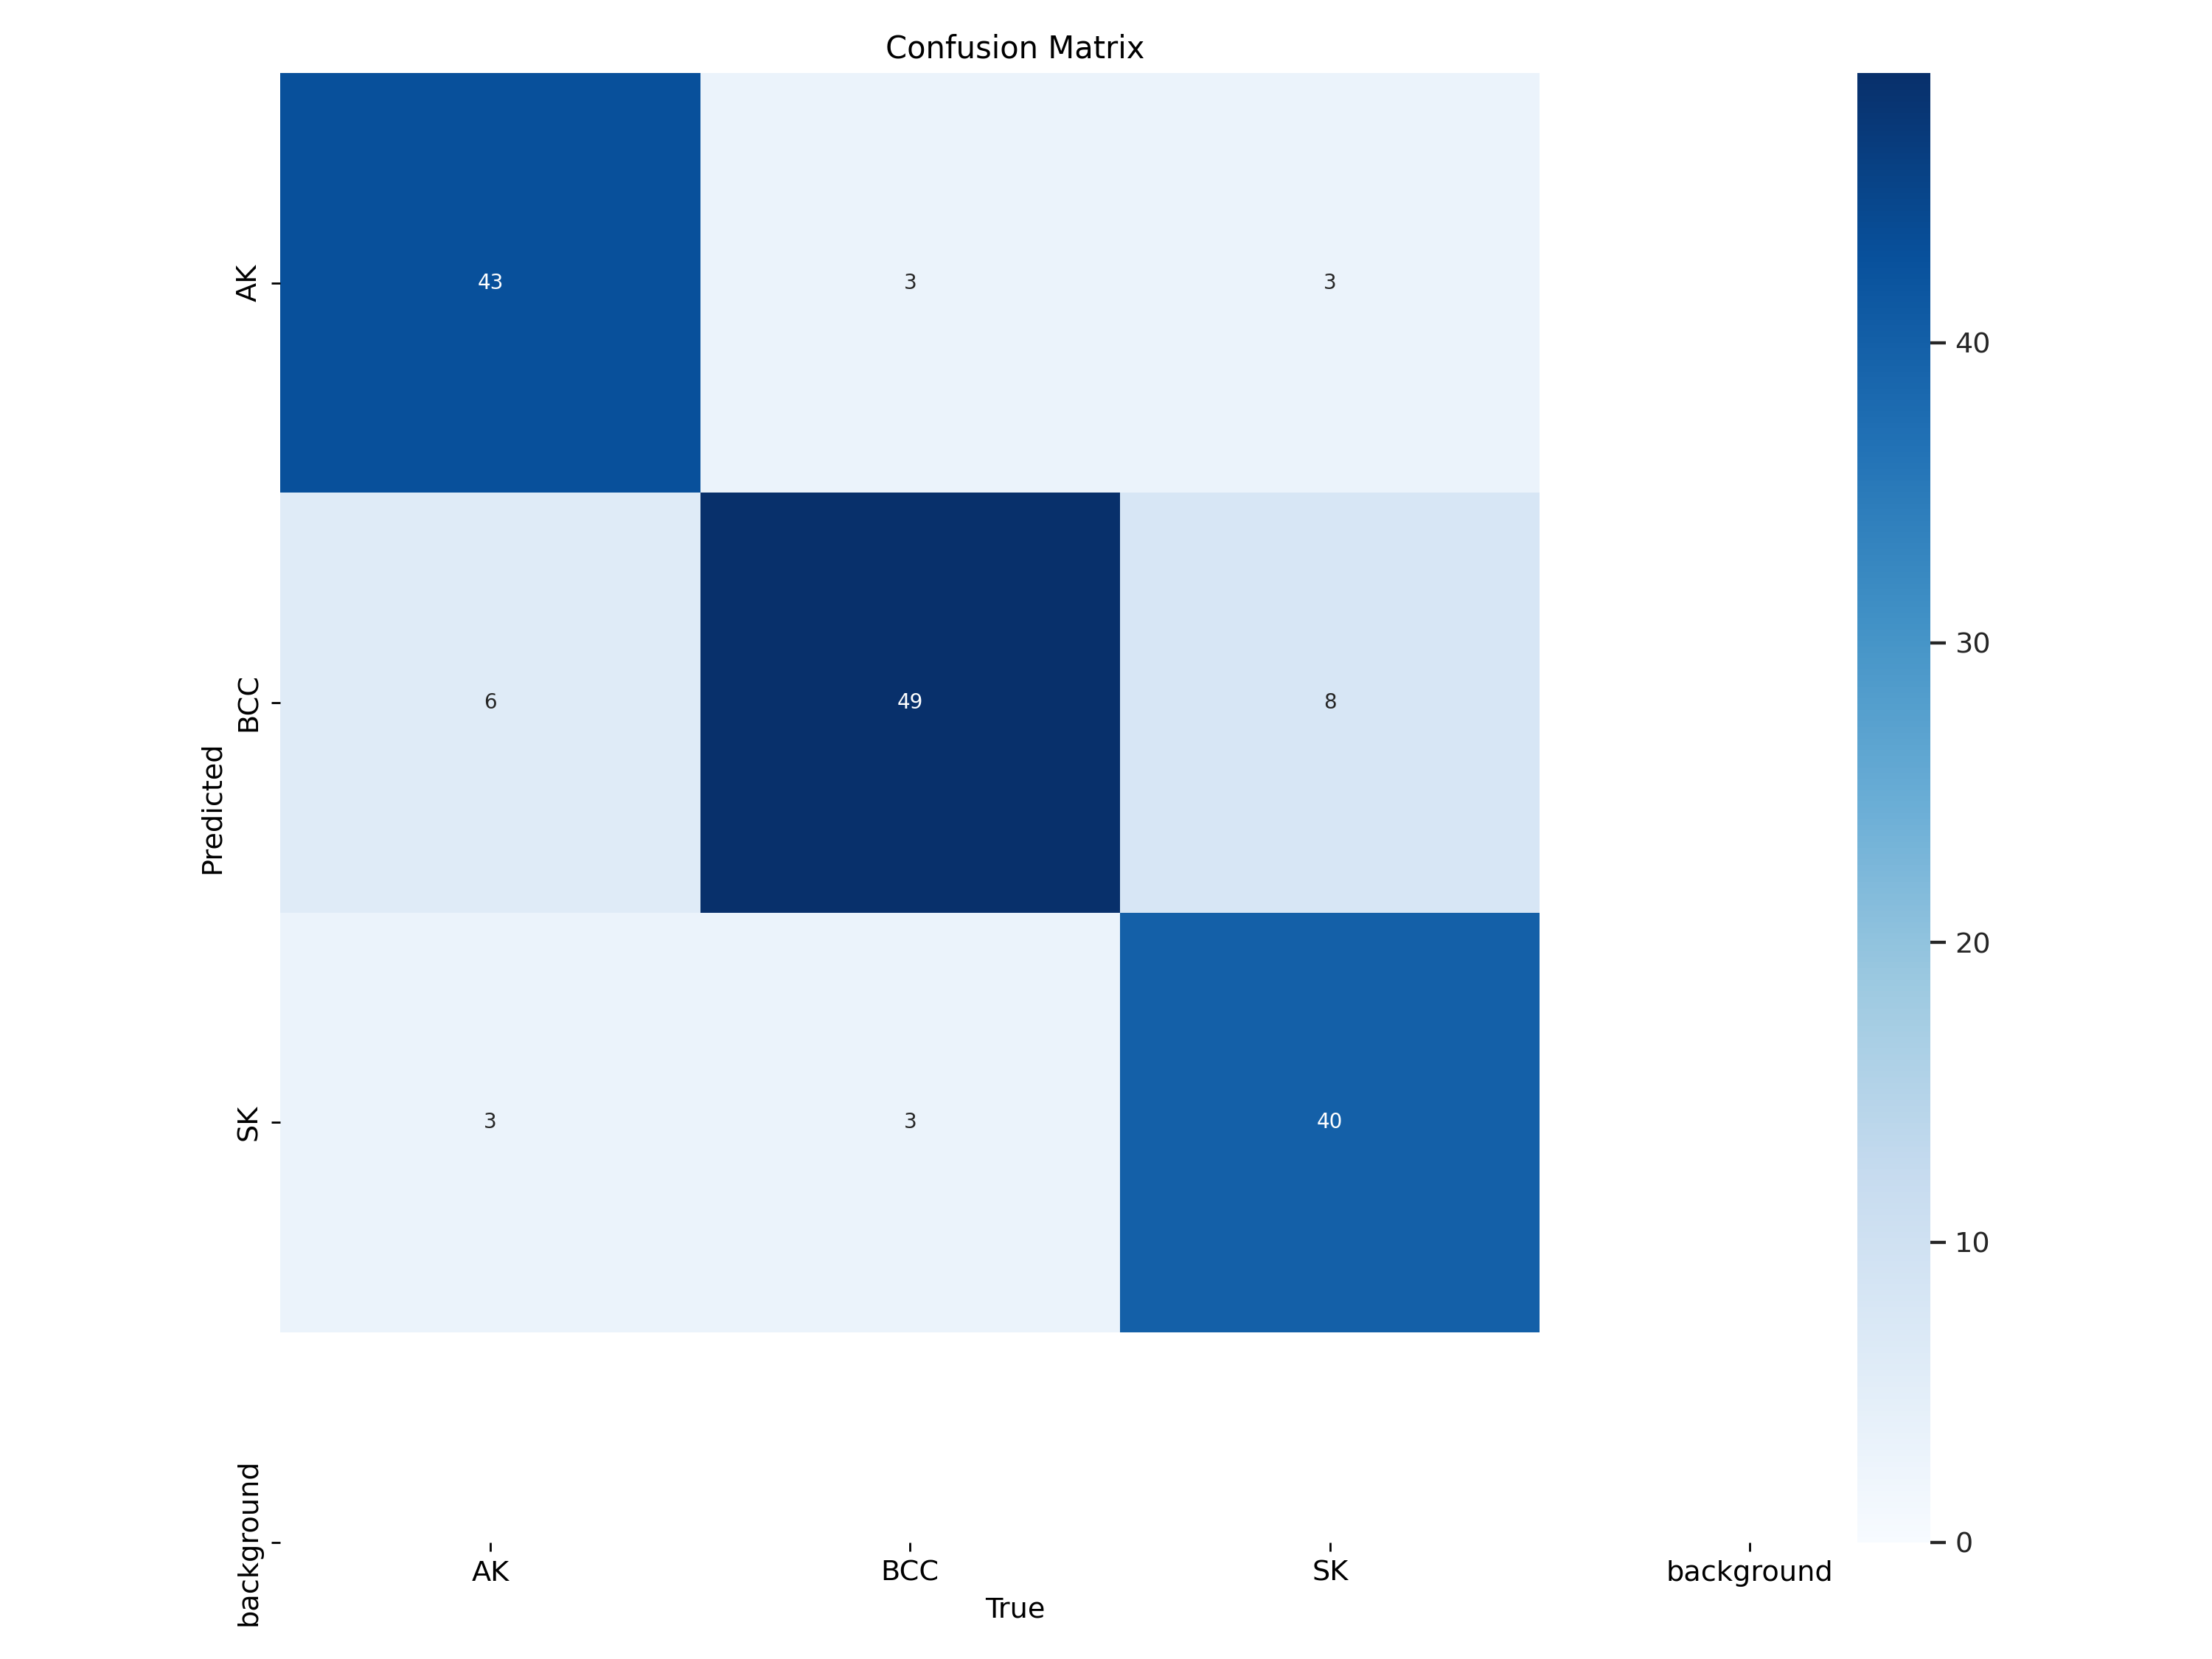

In [ ]:
# prompt: print the confusion matrix in the file /content/runs/train_yolov8x-cls_100_epochs/confusion_matrix.png

from IPython.display import Image
Image(filename='/content/runs/train_yolov8x-cls_100_epochs/confusion_matrix.png', width=700, height=500)


In [ ]:


from sklearn.metrics import classification_report


confusion_matrix = [
    [43, 3, 3],
    [6, 49, 8],
    [3, 3, 40]
]

# Generate classification report
report = classification_report(
    [0] * sum(confusion_matrix[0]) + [1] * sum(confusion_matrix[1]) + [2] * sum(confusion_matrix[2]),
    [0 for _ in range(confusion_matrix[0][0])] + [1 for _ in range(confusion_matrix[0][1])] + [2 for _ in range(confusion_matrix[0][2])] +
    [0 for _ in range(confusion_matrix[1][0])] + [1 for _ in range(confusion_matrix[1][1])] + [2 for _ in range(confusion_matrix[1][2])] +
    [0 for _ in range(confusion_matrix[2][0])] + [1 for _ in range(confusion_matrix[2][1])] + [2 for _ in range(confusion_matrix[2][2])]
)

print(report)


              precision    recall  f1-score   support

           0       0.83      0.88      0.85        49
           1       0.89      0.78      0.83        63
           2       0.78      0.87      0.82        46

    accuracy                           0.84       158
   macro avg       0.83      0.84      0.84       158
weighted avg       0.84      0.84      0.84       158

